In [2]:
import pandas as pd

df = pd.read_csv("World Wildlife Species.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

print("\nColumn Names:")
print(df.columns.tolist())

Dataset loaded successfully!
Dataset Shape: (97, 4)


,Unnamed: 0,Scientifc Name,Common Name,Conservation Status
0,0,Loxodonta africana,African Elephant,NaN
1,1,NaN,African forest elephant,Critically Endangered
2,2,Loxodonta africana africana,African savanna elephant,Endangered
3,3,Lycaon pictus,African Wild Dog,Endangered
4,4,Thunnus alalunga,Albacore Tuna,Near Threatened



Column Names:
['Unnamed: 0', 'Scientifc Name', 'Common Name', 'Conservation Status']


In [3]:
# Check dataset information
print("Dataset Information:")
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())

# Remove duplicate rows
df = df.drop_duplicates()

print("\nAfter Data Cleaning:")
print("Dataset Shape:", df.shape)

display(df.head())

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 97 entries, 0 to 96
Data columns (total 4 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Unnamed: 0           97 non-null     int64
 1   Scientifc Name       87 non-null     str  
 2   Common Name          97 non-null     str  
 3   Conservation Status  82 non-null     str  
dtypes: int64(1), str(3)
memory usage: 2.0 KB

Missing Values:
Unnamed: 0              0
Scientifc Name         10
Common Name             0
Conservation Status    15
dtype: int64

Duplicate Rows: 0

After Data Cleaning:
Dataset Shape: (97, 4)


,Unnamed: 0,Scientifc Name,Common Name,Conservation Status
0,0,Loxodonta africana,African Elephant,NaN
1,1,NaN,African forest elephant,Critically Endangered
2,2,Loxodonta africana africana,African savanna elephant,Endangered
3,3,Lycaon pictus,African Wild Dog,Endangered
4,4,Thunnus alalunga,Albacore Tuna,Near Threatened


In [4]:
print("Column Names:")
print(df.columns.tolist())

Column Names:
['Unnamed: 0', 'Scientifc Name', 'Common Name', 'Conservation Status']


In [6]:
# Reload the original dataset
import pandas as pd

df = pd.read_csv("World Wildlife Species.csv")

# Clean column names
df.columns = df.columns.str.strip()

# Remove unnecessary index column
df = df.loc[:, ~df.columns.str.contains("^Unnamed")]

# Remove duplicate rows
df = df.drop_duplicates()

# Clean text columns
for col in df.select_dtypes(include=["object"]).columns:
    df[col] = df[col].str.strip()

# Fill missing values in text columns
for col in df.select_dtypes(include=["object"]).columns:
    df[col] = df[col].fillna("Unknown")

print("Cleaned Dataset")
print("Shape:", df.shape)
print("Column Names:", df.columns.tolist())
print("\nMissing Values:")
print(df.isnull().sum())

display(df.head(10))

<ipython-input-6-31755deff43e>:16: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include=["object"]).columns:
<ipython-input-6-31755deff43e>:20: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for de

Cleaned Dataset
Shape: (97, 3)
Column Names: ['Scientifc Name', 'Common Name', 'Conservation Status']

Missing Values:
Scientifc Name         0
Common Name            0
Conservation Status    0
dtype: int64


,Scientifc Name,Common Name,Conservation Status
0,Loxodonta africana,African Elephant,Unknown
1,Unknown,African forest elephant,Critically Endangered
2,Loxodonta africana africana,African savanna elephant,Endangered
3,Lycaon pictus,African Wild Dog,Endangered
4,Thunnus alalunga,Albacore Tuna,Near Threatened
5,Scientific Name Inia geoffrensis,Amazon River Dolphin,Unknown
6,Panthera pardus orientalis,Amur Leopard,Critically Endangered
7,Vulpes lagopus,Arctic Fox,Least Concern
8,Canis lupus arctos,Arctic Wolf,Least Concern
9,Elephas maximus indicus,Asian Elephant,Endangered


Species by Conservation Status:
Conservation Status
Endangered               29
Critically Endangered    17
Vulnerable               16
Unknown                  15
Least Concern            12
Near Threatened           8
Name: count, dtype: int64


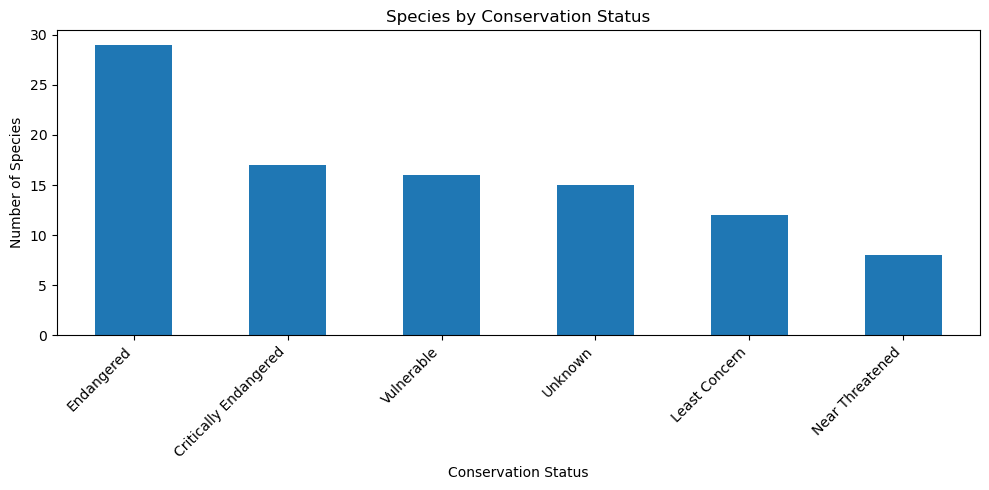

In [7]:
import matplotlib.pyplot as plt

status_counts = df["Conservation Status"].value_counts()

print("Species by Conservation Status:")
print(status_counts)

plt.figure(figsize=(10, 5))
status_counts.plot(kind="bar")

plt.title("Species by Conservation Status")
plt.xlabel("Conservation Status")
plt.ylabel("Number of Species")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

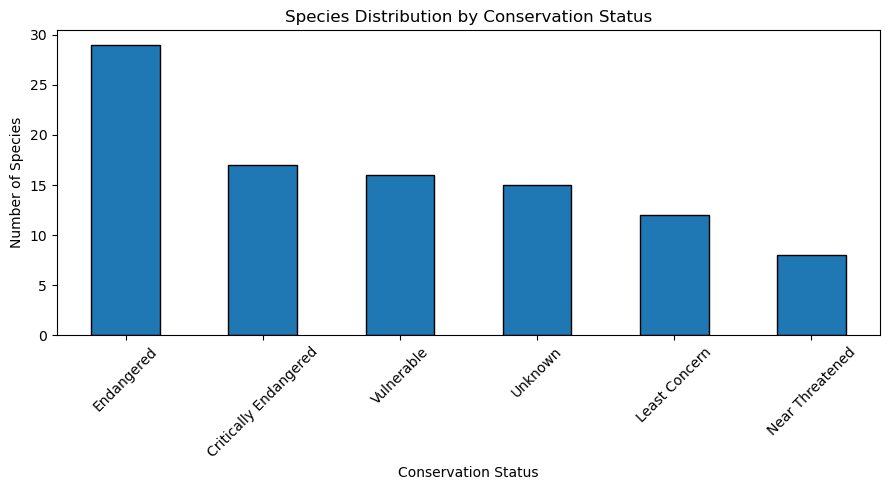

In [8]:
status_counts.plot(
    kind="bar",
    figsize=(9, 5),
    edgecolor="black"
)

plt.title("Species Distribution by Conservation Status")
plt.xlabel("Conservation Status")
plt.ylabel("Number of Species")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [8]:
risk_status = [
    "Critically Endangered",
    "Endangered",
    "Vulnerable"
]

at_risk = df[
    df["Conservation Status"].isin(risk_status)
]

print("Species at Risk:", len(at_risk))
display(at_risk)

Species at Risk: 62


,Scientifc Name,Common Name,Conservation Status
1,NaN,African forest elephant,Critically Endangered
2,Loxodonta africana africana,African savanna elephant,Endangered
3,Lycaon pictus,African Wild Dog,Endangered
6,Panthera pardus orientalis,Amur Leopard,Critically Endangered
9,Elephas maximus indicus,Asian Elephant,Endangered
...,...,...,...
90,Phocoena sinus,Vaquita,Critically Endangered
91,Gorilla gorilla gorilla,Western Lowland Gorilla,Critically Endangered
92,"Balaenoptera, Balaena, Eschrichtius, and Eubalaen",Whale,Endangered
93,Rhincodon typus,Whale Shark,Endangered


Species at Risk:
Conservation Status
Endangered               29
Critically Endangered    17
Vulnerable               16
Name: count, dtype: int64


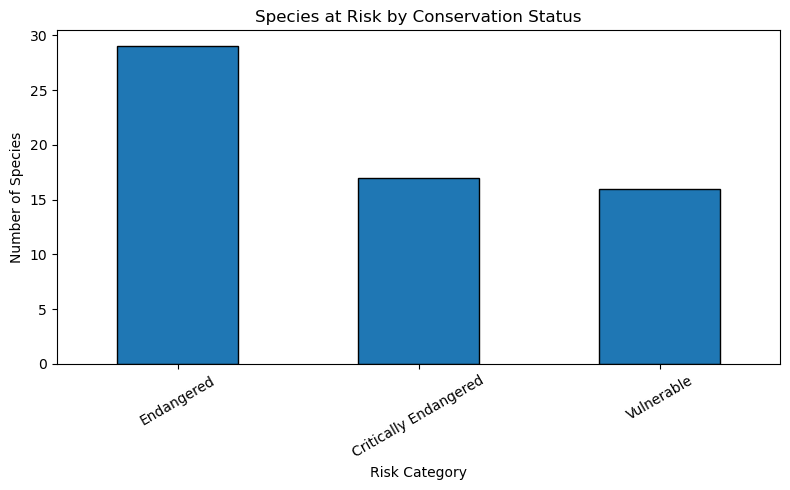

In [10]:
import matplotlib.pyplot as plt

# Identify species at risk
risk_status = [
    "Critically Endangered",
    "Endangered",
    "Vulnerable"
]

at_risk = df[
    df["Conservation Status"].isin(risk_status)
]

# Count species by conservation status
risk_counts = at_risk["Conservation Status"].value_counts()

print("Species at Risk:")
print(risk_counts)

# Plot graph
risk_counts.plot(
    kind="bar",
    figsize=(8, 5),
    edgecolor="black"
)

plt.title("Species at Risk by Conservation Status")
plt.xlabel("Risk Category")
plt.ylabel("Number of Species")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()